

<br><br>

# MACHINE LEARNING ZOOMCAMP - ALEXEY GRIGOREV

<br>

## MODULE 2: Regression (Exploratory Data Analysis) 

<br><br>

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<br>

---

Project Plan:

  - Data Preparation 
  
  - Exploratory Data Analysis

---

<br>


<br><br>

## 2.1. Data Preparation

<br>

In [2]:
data = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/refs/heads/master/chapter-02-car-price/data.csv"

df = pd.read_csv(data)
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [3]:
# Let's see the consistency of the data by checking the columns
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='str')

In [4]:
# Let's correct the column names by removing the spaces and converting them to lowercase
df.columns = df.columns.str.lower().str.replace(" ", "_")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               11914 non-null  str    
 1   model              11914 non-null  str    
 2   year               11914 non-null  int64  
 3   engine_fuel_type   11911 non-null  str    
 4   engine_hp          11845 non-null  float64
 5   engine_cylinders   11884 non-null  float64
 6   transmission_type  11914 non-null  str    
 7   driven_wheels      11914 non-null  str    
 8   number_of_doors    11908 non-null  float64
 9   market_category    8172 non-null   str    
 10  vehicle_size       11914 non-null  str    
 11  vehicle_style      11914 non-null  str    
 12  highway_mpg        11914 non-null  int64  
 13  city_mpg           11914 non-null  int64  
 14  popularity         11914 non-null  int64  
 15  msrp               11914 non-null  int64  
dtypes: float64(3), int64(5), str(8)
m

In [ ]:
# Since "engine_cylinders" and "number_of_doors" are discret numeric values, we can convert them to string type for better analysis
df["engine_cylinders"] = df["engine_cylinders"].astype(str)
df["number_of_doors"] = df["number_of_doors"].astype(str)

In [5]:
strings = list(df.dtypes[df.dtypes == "str"].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [6]:
# I will also convert the string columns to lowercase and replace spaces with underscores for consistency
for col in strings:
    df[col] = df[col].str.lower().str.replace(" ", "_")

df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               11914 non-null  str    
 1   model              11914 non-null  str    
 2   year               11914 non-null  int64  
 3   engine_fuel_type   11911 non-null  str    
 4   engine_hp          11845 non-null  float64
 5   engine_cylinders   11884 non-null  float64
 6   transmission_type  11914 non-null  str    
 7   driven_wheels      11914 non-null  str    
 8   number_of_doors    11908 non-null  float64
 9   market_category    8172 non-null   str    
 10  vehicle_size       11914 non-null  str    
 11  vehicle_style      11914 non-null  str    
 12  highway_mpg        11914 non-null  int64  
 13  city_mpg           11914 non-null  int64  
 14  popularity         11914 non-null  int64  
 15  msrp               11914 non-null  int64  
dtypes: float64(3), int64(5), str(8)
m

---

<br><br>

## 2.2. Exploratory Data Analysis

<br>

In [ ]:
# Lets get to know our data a little better
for col in df.columns:
    print(f"Columns: {col}\n")
    print(f"Unique Values: {list(df[col].unique()[:9])}\n")
    print(f"How many Unique Values has  '{col}' : {df[col].nunique()}\n")
    print("-" * 60)

Columns: make

Unique Values: ['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler', 'nissan', 'volvo', 'mazda', 'mitsubishi']

How many Unique Values has  'make' : 48

------------------------------------------------------------
Columns: model

Unique Values: ['1_series_m', '1_series', '100', '124_spider', '190-class', '2_series', '200', '200sx', '240sx']

How many Unique Values has  'model' : 914

------------------------------------------------------------
Columns: year

Unique Values: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(2017), np.int64(1991), np.int64(2016)]

How many Unique Values has  'year' : 28

------------------------------------------------------------
Columns: engine_fuel_type

Unique Values: ['premium_unleaded_(required)', 'regular_unleaded', 'premium_unleaded_(recommended)', 'flex-fuel_(unleaded/e85)', 'diesel', 'electric', 'flex-fuel_(premium_unleaded_recommended/e85)', 'natural_gas', 'flex-fuel_(premium

---

<br>


### Distribution of the Price

<br>

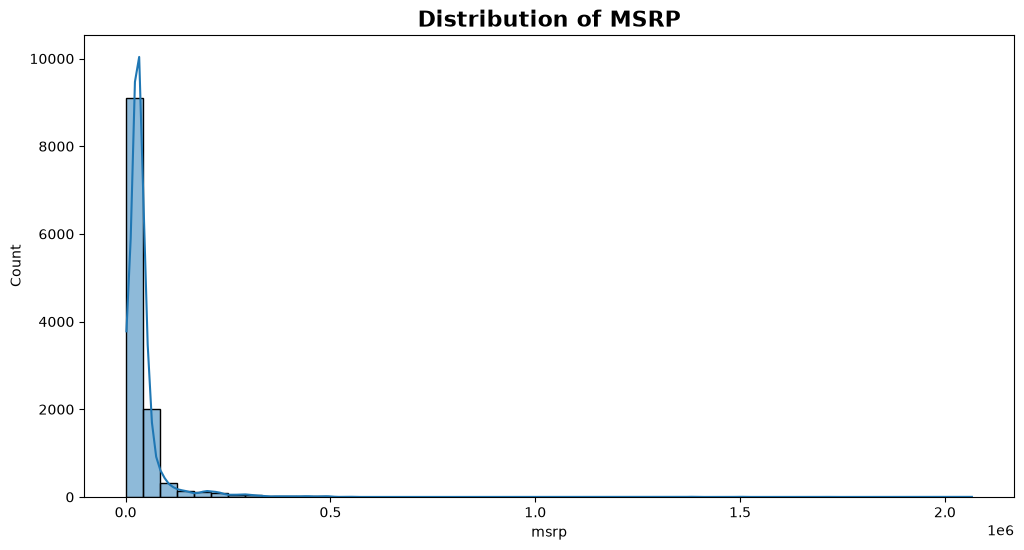

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x="msrp", bins=50, kde=True)
plt.title("Distribution of MSRP", fontsize=16, fontweight="bold")
plt.show()

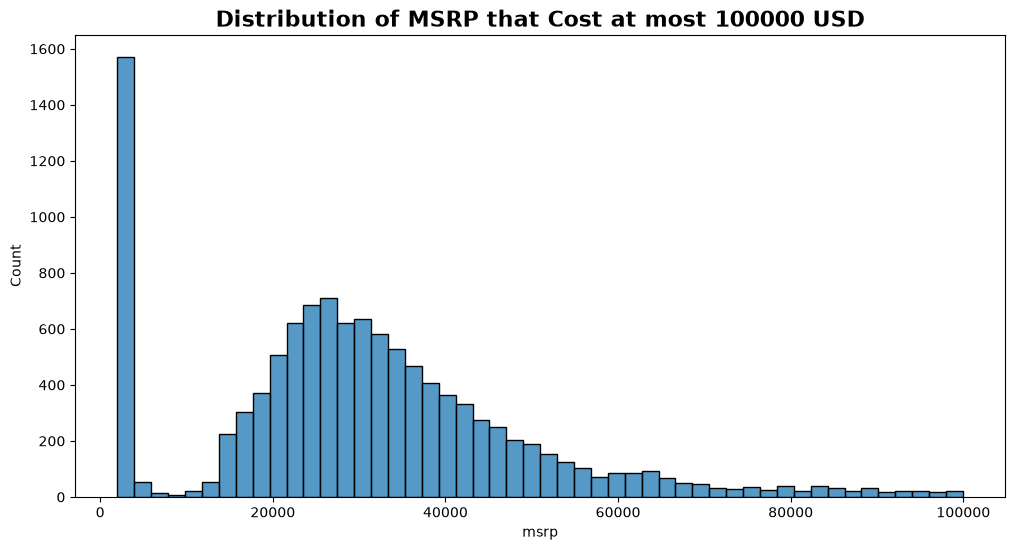

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df.msrp[df.msrp < 100000], bins=50)
plt.title(
    "Distribution of MSRP that Cost at most 100000 USD", fontsize=16, fontweight="bold"
)
plt.show()

---

Thanks to the upper plot we can see that there are **several cheaper cars**, but on the other hand there so little expensive cars

---